In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
try:
    data = pd.read_csv("Wholesale customers data.csv")
except FileNotFoundError:
    url = "https://raw.githubusercontent.com/TrainingByPackt/Data-Science-with-Python/master/Chapter01/Data/Wholesale%20customers%20data.csv"
    data = pd.read_csv(url)

data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Missing values count per feature:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


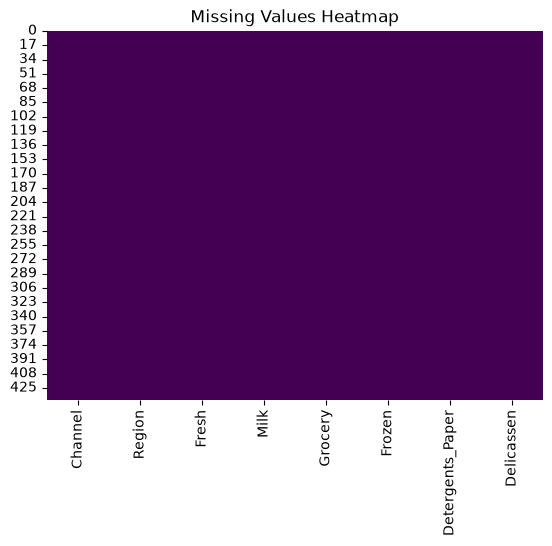

In [3]:
print("Missing values count per feature:")
print(data.isnull().sum())

sns.heatmap(data.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

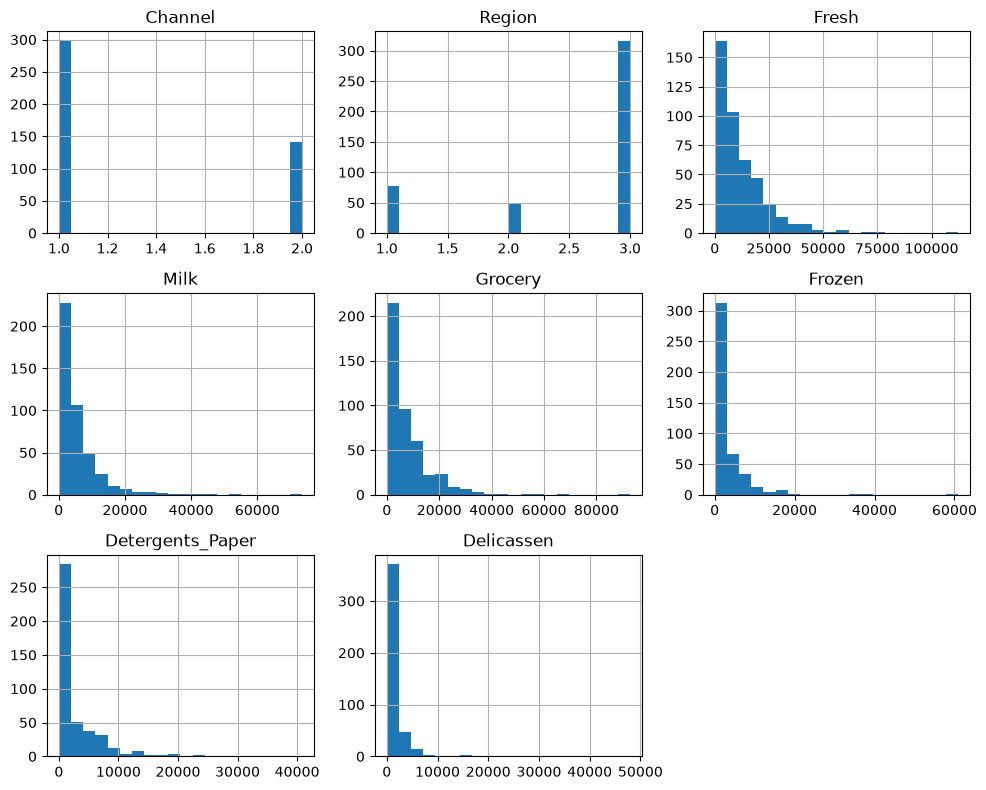

Dataset shape after outlier removal: (396, 8)


In [4]:
data.hist(figsize=(10, 8), bins=20)
plt.tight_layout()
plt.show()

for column in data.columns:
    mean = data[column].mean()
    std = data[column].std()
    
    min_val = mean - (3 * std)
    max_val = mean + (3 * std)
    
    # Filter rows within range
    data = data[(data[column] >= min_val) & (data[column] <= max_val)]

print("Dataset shape after outlier removal:", data.shape)

In [5]:
scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)

data_scaled.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.572795,0.580937,0.182209,1.243583,0.248565,-0.814406,0.270208,0.149495
1,1.572795,0.580937,-0.385451,1.280942,0.609337,-0.275530,0.516090,0.554714
2,-0.635811,0.580937,0.242495,-0.808690,-0.351823,1.340402,-0.590575,0.565816
3,1.572795,0.580937,1.188258,0.213565,0.183313,0.473953,-0.086101,3.708576
4,1.572795,0.580937,-0.147139,0.904692,-0.189143,-0.657060,-0.078951,0.254038
